In [1]:
import pandas as pd

df = pd.read_parquet(
    "../data/yellow_tripdata_2023-01.parquet"
)

print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

df.head()

Shape: (3066766, 19)
Columns: ['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime', 'passenger_count', 'trip_distance', 'RatecodeID', 'store_and_fwd_flag', 'PULocationID', 'DOLocationID', 'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount', 'congestion_surcharge', 'airport_fee']


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee
0,2,2023-01-01 00:32:10,2023-01-01 00:40:36,1.0,0.97,1.0,N,161,141,2,9.3,1.00,0.5,0.00,0.0,1.0,14.30,2.5,0.00
1,2,2023-01-01 00:55:08,2023-01-01 01:01:27,1.0,1.10,1.0,N,43,237,1,7.9,1.00,0.5,4.00,0.0,1.0,16.90,2.5,0.00
2,2,2023-01-01 00:25:04,2023-01-01 00:37:49,1.0,2.51,1.0,N,48,238,1,14.9,1.00,0.5,15.00,0.0,1.0,34.90,2.5,0.00
3,1,2023-01-01 00:03:48,2023-01-01 00:13:25,0.0,1.90,1.0,N,138,7,1,12.1,7.25,0.5,0.00,0.0,1.0,20.85,0.0,1.25
4,2,2023-01-01 00:10:29,2023-01-01 00:21:19,1.0,1.43,1.0,N,107,79,1,11.4,1.00,0.5,3.28,0.0,1.0,19.68,2.5,0.00


In [2]:
df["duration"] = (
    df["tpep_dropoff_datetime"]
    - df["tpep_pickup_datetime"]).dt.total_seconds() / 60

df["duration"].describe()

count    3.066766e+06
mean     1.566900e+01
std      4.259435e+01
min     -2.920000e+01
25%      7.116667e+00
50%      1.151667e+01
75%      1.830000e+01
max      1.002918e+04
Name: duration, dtype: float64

In [3]:
negative_trips = df[df["duration"] < 0]

print("Negative trips:", len(negative_trips))

negative_trips[
    [
        "tpep_pickup_datetime",
        "tpep_dropoff_datetime",
        "duration",
    ]
].head(10)

Negative trips: 3


,tpep_pickup_datetime,tpep_dropoff_datetime,duration
1839180,2023-01-20 13:35:00,2023-01-20 13:05:48,-29.200000
2124414,2023-01-23 10:43:58,2023-01-23 10:29:26,-14.533333
2218504,2023-01-24 11:00:00,2023-01-24 10:40:48,-19.200000


In [4]:
print("Before filtering:")
print(df["duration"].std())

df_clean = df[
    df["duration"].between(1, 60)
].copy()

print("\nAfter filtering:")
print(df_clean["duration"].describe())

print("\nPercentage retained:")
print(round(len(df_clean) / len(df) * 100, 2))

Before filtering:
42.59435124195458

After filtering:
count    3.009173e+06
mean     1.420486e+01
std      9.939386e+00
min      1.000000e+00
25%      7.216667e+00
50%      1.155000e+01
75%      1.818333e+01
max      6.000000e+01
Name: duration, dtype: float64

Percentage retained:
98.12


Note: you may need to restart the kernel to use updated packages.


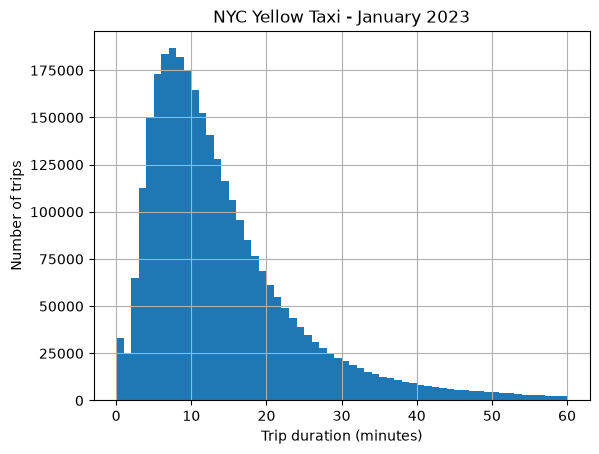

In [5]:
%pip install matplotlib

import matplotlib.pyplot as plt

df["duration"].hist(bins=60, range=(0,60))
plt.xlabel("Trip duration (minutes)")
plt.ylabel("Number of trips")
plt.title("NYC Yellow Taxi - January 2023")
plt.show()

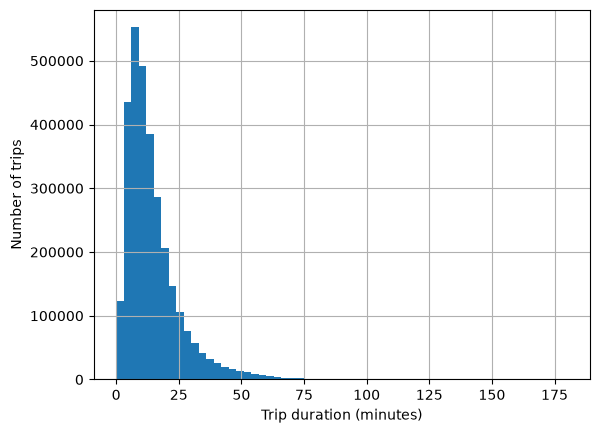

In [6]:
df["duration"].hist(bins=60, range=(0,180))
plt.xlabel("Trip duration (minutes)")
plt.ylabel("Number of trips")
plt.show()

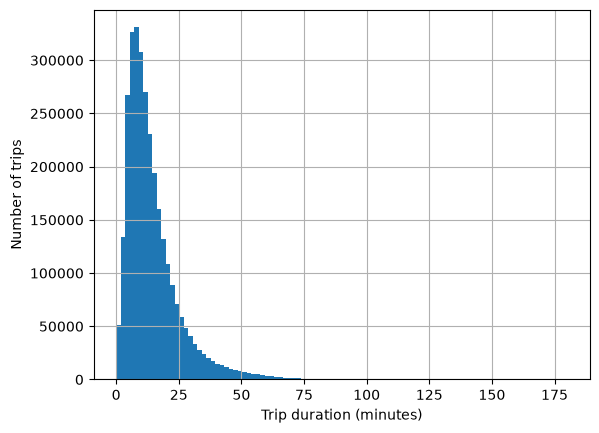

In [7]:
df["duration"].hist(bins=100, range=(0, 180))
plt.xlabel("Trip duration (minutes)")
plt.ylabel("Number of trips")
plt.show()

In [8]:
from sklearn.feature_extraction import DictVectorizer

categorical = ["PULocationID", "DOLocationID"]

train_dicts = (
    df_clean[categorical].astype(str).to_dict(orient="records")
)

dv = DictVectorizer(sparse=True)
X_train = dv.fit_transform(train_dicts)

print("Feature matrix shape:", X_train.shape)
print("First feature names:", dv.feature_names_[:10])

Feature matrix shape: (3009173, 515)
First feature names: ['DOLocationID=1', 'DOLocationID=10', 'DOLocationID=100', 'DOLocationID=101', 'DOLocationID=102', 'DOLocationID=106', 'DOLocationID=107', 'DOLocationID=108', 'DOLocationID=109', 'DOLocationID=11']


In [9]:
features = dv.get_feature_names_out()

pickup_features = [
    f for f in features
    if f.startswith("PULocationID=")
]

dropoff_features = [
    f for f in features
    if f.startswith("DOLocationID=")
]

print("Pickup features:", len(pickup_features))
print("Dropoff features:", len(dropoff_features))
print("Total:", len(features))
print("\nFirst 10 pickup features:")
print(pickup_features[:10])



Pickup features: 255
Dropoff features: 260
Total: 515

First 10 pickup features:
['PULocationID=1', 'PULocationID=10', 'PULocationID=100', 'PULocationID=101', 'PULocationID=102', 'PULocationID=106', 'PULocationID=107', 'PULocationID=108', 'PULocationID=109', 'PULocationID=11']


In [10]:
row = X_train[0]

print("Original locations:")
print(df_clean[categorical].iloc[0])
print("\nEncoded non zero features:")
print([
    (features[i], row[0,i])
    for i in row.indices
])

Original locations:
PULocationID    161
DOLocationID    141
Name: 0, dtype: int64

Encoded non zero features:
[('DOLocationID=141', np.float64(1.0)), ('PULocationID=161', np.float64(1.0))]


In [11]:
print("Number of columns:", X_train.shape[1])
print("Nonzero features in first trip:", X_train[0].nnz)
print("Nonzero values in entire matrix:", X_train.nnz)

Number of columns: 515
Nonzero features in first trip: 2
Nonzero values in entire matrix: 6018346


In [12]:
y_train = df_clean["duration"].to_numpy()

print("Features shape:", X_train.shape)
print("Target shape:", y_train.shape)

print("First 5 durations:", y_train[:5])

Features shape: (3009173, 515)
Target shape: (3009173,)
First 5 durations: [ 8.43333333  6.31666667 12.75        9.61666667 10.83333333]


In [13]:
%%time

from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

print("Model trained successfully!")
print("Coefficients:", model.coef_.shape)
print("Intercept:", model.intercept_)

Model trained successfully!
Coefficients: (515,)
Intercept: 23.195193134658137
CPU times: user 12min 43s, sys: 29.4 s, total: 13min 12s
Wall time: 52.2 s


In [14]:
pickup_idx = dv.vocabulary_["PULocationID=161"]
dropoff_idx = dv.vocabulary_["DOLocationID=141"]

print("Intercept:", model.intercept_)
print("Pickup weight:", model.coef_[pickup_idx])
print("Dropoff weight:", model.coef_[dropoff_idx])

print(
    "Predicted duration:",
    model.intercept_
    + model.coef_[pickup_idx]
    + model.coef_[dropoff_idx]
)

Intercept: 23.195193134658137
Pickup weight: -5.701319604884633
Dropoff weight: -5.966711095289375
Predicted duration: 11.527162434484127


In [15]:
predictions = model.predict(X_train[:5])

for actual, predicted in zip(y_train[:5], predictions):
    print(
        f"Actual: {actual:.2f} min | "
        f"Predicted: {predicted:.2f} min"
    )

Actual: 8.43 min | Predicted: 11.53 min
Actual: 6.32 min | Predicted: 10.90 min
Actual: 12.75 min | Predicted: 11.33 min
Actual: 9.62 min | Predicted: 27.92 min
Actual: 10.83 min | Predicted: 11.70 min


In [16]:
from sklearn.metrics import root_mean_squared_error

y_pred = model.predict(X_train)

rmse = root_mean_squared_error(y_train, y_pred)

print(f"Training RMSE: {rmse:4f} minutes")

for actual, predicted in zip(y_train[:5], y_pred[:5]):
    print(
        f"Actual: {actual:.2f} min | "
        f"Predicted: {predicted:.2f} min"
    )

Training RMSE: 7.649262 minutes
Actual: 8.43 min | Predicted: 11.53 min
Actual: 6.32 min | Predicted: 10.90 min
Actual: 12.75 min | Predicted: 11.33 min
Actual: 9.62 min | Predicted: 27.92 min
Actual: 10.83 min | Predicted: 11.70 min


In [17]:
import pandas as pd

df_val = pd.read_parquet(
    "../data/yellow_tripdata_2023-02.parquet"
)

df_val["duration"] = (
    df_val["tpep_dropoff_datetime"]
    - df_val["tpep_pickup_datetime"]
).dt.total_seconds() / 60

df_val = df_val[
    df_val["duration"].between(1, 60)
].copy()

print("Validation records:", len(df_val))

Validation records: 2855951


In [18]:
val_dicts = (
    df_val[categorical]
    .astype(str)
    .to_dict(orient="records")
)

X_val = dv.transform(val_dicts)

y_val = df_val["duration"].to_numpy()

print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)

Training shape: (3009173, 515)
Validation shape: (2855951, 515)


In [19]:
from sklearn.metrics import root_mean_squared_error

y_val_pred = model.predict(X_val)

val_rmse = root_mean_squared_error(
    y_val, y_val_pred
)

print(f"Training RMSE: {rmse:.4f} min")
print(f"Validation RMSE: {val_rmse:.4f} min")
print(f"Difference: {val_rmse - rmse:+.4f} min")

      

Training RMSE: 7.6493 min
Validation RMSE: 7.8118 min
Difference: +0.1626 min


## Results — NYC Taxi Duration Prediction

**Dataset:** NYC Yellow Taxi, January–February 2023

**Objective:** Predict taxi trip duration in minutes.

**Approach:**
- Filter trips to durations between 1 and 60 minutes.
- One-hot encode pickup and dropoff location IDs.
- Train a linear regression model on January records.
- Validate against February records without refitting.

**Results:**

| Metric | Value |
|---|---:|
| Training samples | 3,009,173 |
| Validation samples | 2,855,951 |
| Encoded features | 515 |
| Training RMSE | 7.6493 min |
| Validation RMSE | 7.8118 min |

**Conclusion:** The model exhibits similar performance on training and validation data, with a 2.13% increase in RMSE. However, its predictions remain limited by the small feature set, which excludes traffic, departure time, and route information.